# NB10: FreeSurfer QC

> **Local pipeline required.** This notebook inspects FreeSurfer outputs and cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose
Quality control of FreeSurfer recon-all outputs. Verify cortical surfaces,
parcellation labels, and subcortical segmentations for all subjects and sessions.

## Interactive Inspection
For detailed 3D inspection, use the freeview script:
```bash
bash scripts/freeview_freesurfer.sh --subject PAT16 --session preop
```

## Standard vs. Clinical
Two FreeSurfer reconstruction scripts are available:
- `run_freesurfer.sh` -- standard `recon-all` (best cortical thickness accuracy)
- `run_freesurfer_clinical.sh` -- `recon-all-clinical` using SynthSeg + SynthDist
  (robust to tumors, resection cavities, and abnormal anatomy)

For post-op sessions with resection cavities, `recon-all-clinical` is
recommended. The clinical variant also produces `synthSR.mgz` (synthesized
MPRAGE) and `synthseg.mgz` (robust volumetric segmentation).

## QC Checklist
- [ ] Pial surfaces follow the cortical ribbon (no over/under-estimation)
- [ ] White matter surfaces correctly segment WM/GM boundary
- [ ] aparc+aseg labels are anatomically plausible
- [ ] Ventricles correctly segmented (especially post-op with cavity)
- [ ] No topology errors in surfaces
- [ ] For clinical: check synthSR.mgz quality near lesion boundaries

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
FS_DIR = DERIV_ROOT / 'freesurfer'
SUBJECTS = ['PAT16']
SESSIONS = ['preop', 'postop']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Inventory of FreeSurfer Outputs

In [2]:
key_files = [
    'mri/T1.mgz', 'mri/aparc+aseg.mgz', 'mri/aseg.mgz',
    'mri/brainmask.mgz', 'mri/wm.mgz', 'mri/brain.mgz',
    'surf/lh.white', 'surf/rh.white', 'surf/lh.pial', 'surf/rh.pial',
    'label/lh.aparc.annot', 'label/rh.aparc.annot',
    'stats/aseg.stats', 'stats/lh.aparc.stats', 'stats/rh.aparc.stats',
]

print(f'{"File":<35s}', end='')
for sub in SUBJECTS:
    for ses in SESSIONS:
        print(f'  {sub[:5]}/{ses[:4]}', end='')
print()
print('-' * (35 + 12 * len(SUBJECTS) * len(SESSIONS)))

for f in key_files:
    print(f'{f:<35s}', end='')
    for sub in SUBJECTS:
        for ses in SESSIONS:
            path = FS_DIR / f'sub-{sub}_ses-{ses}' / f
            mark = '  OK' if path.exists() else '  --'
            print(f'{mark:>10s}', end='')
    print()

File                                 PAT16/preo  PAT16/post
-----------------------------------------------------------
mri/T1.mgz                                 OK        --
mri/aparc+aseg.mgz                         OK        OK
mri/aseg.mgz                               OK        OK
mri/brainmask.mgz                          OK        OK
mri/wm.mgz                                 OK        OK
mri/brain.mgz                              OK        OK
surf/lh.white                              OK        OK
surf/rh.white                              OK        OK
surf/lh.pial                               OK        OK
surf/rh.pial                               OK        OK
label/lh.aparc.annot                       OK        OK
label/rh.aparc.annot                       OK        OK
stats/aseg.stats                           OK        --
stats/lh.aparc.stats                       OK        OK
stats/rh.aparc.stats                       OK        OK


## 2. Parcellation Volume Statistics

In [3]:
try:
    import nibabel as nib

    DK_LABELS = {
        2: 'L-Cerebral-WM', 3: 'L-Cortex', 4: 'L-Lat-Ventricle',
        10: 'L-Thalamus', 11: 'L-Caudate', 17: 'L-Hippocampus',
        41: 'R-Cerebral-WM', 42: 'R-Cortex', 43: 'R-Lat-Ventricle',
        49: 'R-Thalamus', 50: 'R-Caudate', 53: 'R-Hippocampus',
    }

    for sub in SUBJECTS:
        print(f'\n=== sub-{sub} ===')
        for ses in SESSIONS:
            aparc_path = FS_DIR / f'sub-{sub}_ses-{ses}' / 'mri' / 'aparc+aseg.mgz'
            if not aparc_path.exists():
                print(f'  ses-{ses}: not available')
                continue
            img = nib.load(str(aparc_path))
            data = np.asarray(img.dataobj)
            vox_vol = np.prod(img.header.get_zooms()[:3])

            print(f'\n  ses-{ses}:')
            print(f'    {"ROI":<25s} {"Volume (mm3)":>12s} {"Volume (cm3)":>12s}')
            print('    ' + '-' * 52)
            for lab, name in sorted(DK_LABELS.items()):
                count = int(np.sum(data == lab))
                vol_mm3 = count * vox_vol
                vol_cm3 = vol_mm3 / 1000.0
                print(f'    {name:<25s} {vol_mm3:>12.1f} {vol_cm3:>12.2f}')
except ImportError:
    print('nibabel not available -- install to inspect volumes')
except Exception as e:
    print(f'Could not load parcellation: {e}')


=== sub-PAT16 ===



  ses-preop:
    ROI                       Volume (mm3) Volume (cm3)
    ----------------------------------------------------
    L-Cerebral-WM                 254779.0       254.78


    L-Cortex                           0.0         0.00
    L-Lat-Ventricle                12392.0        12.39
    L-Thalamus                      6885.0         6.88
    L-Caudate                       3985.0         3.98
    L-Hippocampus                   4099.0         4.10
    R-Cerebral-WM                 229382.0       229.38
    R-Cortex                           0.0         0.00
    R-Lat-Ventricle                13117.0        13.12
    R-Thalamus                      6404.0         6.40
    R-Caudate                       3938.0         3.94
    R-Hippocampus                   3675.0         3.67

  ses-postop:
    ROI                       Volume (mm3) Volume (cm3)
    ----------------------------------------------------
    L-Cerebral-WM                 237350.0       237.35
    L-Cortex                           0.0         0.00
    L-Lat-Ventricle                13612.0        13.61


    L-Thalamus                      6802.0         6.80
    L-Caudate                       3641.0         3.64
    L-Hippocampus                   4020.0         4.02
    R-Cerebral-WM                 210842.0       210.84


    R-Cortex                           0.0         0.00
    R-Lat-Ventricle                18127.0        18.13
    R-Thalamus                      6257.0         6.26
    R-Caudate                       3696.0         3.70
    R-Hippocampus                   3393.0         3.39


## 3. Visual QC: Overlay aparc+aseg on T1w

Display axial slices with parcellation overlay for quick inline QC.
For full 3D inspection, use freeview:

```bash
bash scripts/freeview_freesurfer.sh --subject PAT16 --session preop
```

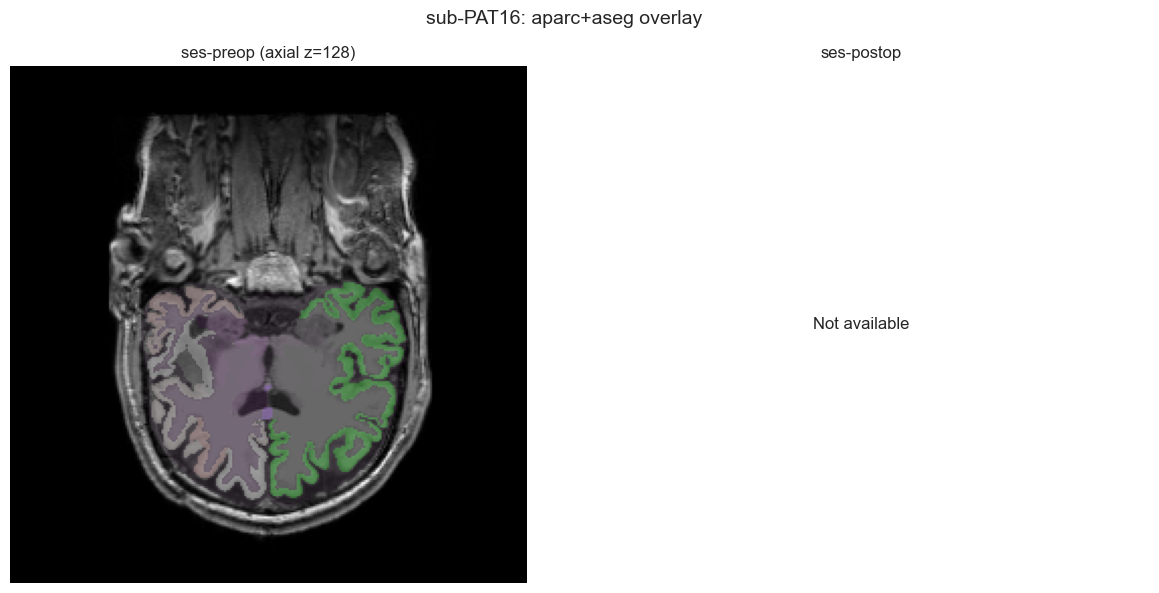

In [4]:
try:
    import nibabel as nib
    from matplotlib.colors import ListedColormap

    for sub in SUBJECTS:
        fig, axes = plt.subplots(1, len(SESSIONS), figsize=(6 * len(SESSIONS), 6))
        if len(SESSIONS) == 1:
            axes = [axes]
        fig.suptitle(f'sub-{sub}: aparc+aseg overlay', fontsize=14)

        for idx, ses in enumerate(SESSIONS):
            t1_path = FS_DIR / f'sub-{sub}_ses-{ses}' / 'mri' / 'T1.mgz'
            aparc_path = FS_DIR / f'sub-{sub}_ses-{ses}' / 'mri' / 'aparc+aseg.mgz'
            ax = axes[idx]

            if t1_path.exists() and aparc_path.exists():
                t1 = np.asarray(nib.load(str(t1_path)).dataobj)
                aparc = np.asarray(nib.load(str(aparc_path)).dataobj)
                mid = t1.shape[2] // 2
                ax.imshow(np.rot90(t1[:, :, mid]), cmap='gray')
                mask = aparc[:, :, mid] > 0
                overlay = np.ma.masked_where(~mask, aparc[:, :, mid])
                ax.imshow(np.rot90(overlay), cmap='nipy_spectral', alpha=0.3)
                ax.set_title(f'ses-{ses} (axial z={mid})')
            else:
                ax.text(0.5, 0.5, 'Not available', ha='center', va='center',
                        transform=ax.transAxes, fontsize=12)
                ax.set_title(f'ses-{ses}')
            ax.axis('off')

        plt.tight_layout()
        plt.show()
except Exception as e:
    print(f'Visual QC not available: {e}')

## 4. Surface Statistics

Check Euler numbers and surface vertex counts for topology verification.

In [5]:
for sub in SUBJECTS:
    print(f'\n=== sub-{sub} ===')
    for ses in SESSIONS:
        fs_subj = FS_DIR / f'sub-{sub}_ses-{ses}'
        stats_file = fs_subj / 'stats' / 'aseg.stats'
        if stats_file.exists():
            print(f'  ses-{ses}: aseg.stats found')
            with open(stats_file) as f:
                for line in f:
                    if 'BrainSegVol' in line or 'eTIV' in line:
                        print(f'    {line.strip()}')
        else:
            print(f'  ses-{ses}: not available')

        for hemi in ['lh', 'rh']:
            surf_path = fs_subj / 'surf' / f'{hemi}.white'
            if surf_path.exists():
                size_mb = surf_path.stat().st_size / 1e6
                print(f'    {hemi}.white: {size_mb:.1f} MB')


=== sub-PAT16 ===
  ses-preop: aseg.stats found
    # Measure BrainSeg, BrainSegVol, Brain Segmentation Volume, 1487441.000000, mm^3
    # Measure BrainSegNotVent, BrainSegVolNotVent, Brain Segmentation Volume Without Ventricles, 1099530.000000, mm^3
    # Measure BrainSegVol-to-eTIV, BrainSegVol-to-eTIV, Ratio of BrainSegVol to eTIV, 0.926701, unitless
    # Measure MaskVol-to-eTIV, MaskVol-to-eTIV, Ratio of MaskVol to eTIV, 0.976011, unitless
    # Measure EstimatedTotalIntraCranialVol, eTIV, Estimated Total Intracranial Volume, 1605092.165344, mm^3
    lh.white: 5.1 MB
    rh.white: 4.9 MB
  ses-postop: not available
    lh.white: 4.5 MB
    rh.white: 4.2 MB
